In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'
from pathlib import Path

# pytorch relates imports

import torch
import torch.nn as nn
import torch.optim as optim

# imports from captum library
from captum.attr import IntegratedGradients, Saliency, Occlusion

import pandas as pd
pd.DataFrame.iteritems = pd.DataFrame.items

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
import matplotlib.transforms as transforms
import matplotlib.patches as patches
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib import ticker


import scipy

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, KernelPCA

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.neural_network import MLPClassifier
from sklearn import metrics
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
ann_pca_filename = "Performance Dictionaries\\Performance_ANN_PCA_nCV.pkl"

with open(ann_pca_filename, "rb") as file:
    ANN_pca_loaded_performance = pickle.load(file)
print(ANN_pca_loaded_performance.keys())

ann_full_filename = "Performance Dictionaries\\Performance_ANN_nCV.pkl"

with open(ann_full_filename, "rb") as file:
    ANN_full_loaded_performance = pickle.load(file)
print(ANN_full_loaded_performance.keys())

datasetname = "Preprocessed_Raman_Spectra_2025.pkl"

with open(datasetname, "rb") as file:
    loaded_data = pickle.load(file)
print(loaded_data.keys())

dict_keys(['CV 1', 'CV 2', 'CV 3'])
dict_keys(['CV 1', 'CV 2', 'CV 3'])
dict_keys(['Spectra', 'wavenumber', 'species label', 'culture age', 'culture condition', 'biological replicate', 'technical replicate', 'Preprocess conditions'])


In [3]:
svc_pca_filename = "Performance Dictionaries\\Performance_SVC_PCA_nCV.pkl"

with open(svc_pca_filename, "rb") as file:
    SVC_pca_loaded_performance = pickle.load(file)
print(SVC_pca_loaded_performance.keys())

svc_full_filename = "Performance Dictionaries\\Performance_SVC_nCV.pkl"

with open(svc_full_filename, "rb") as file:
    SVC_full_loaded_performance = pickle.load(file)
print(SVC_full_loaded_performance.keys())

dict_keys(['CV 1', 'CV 2', 'CV 3'])
dict_keys(['CV 1', 'CV 2', 'CV 3'])


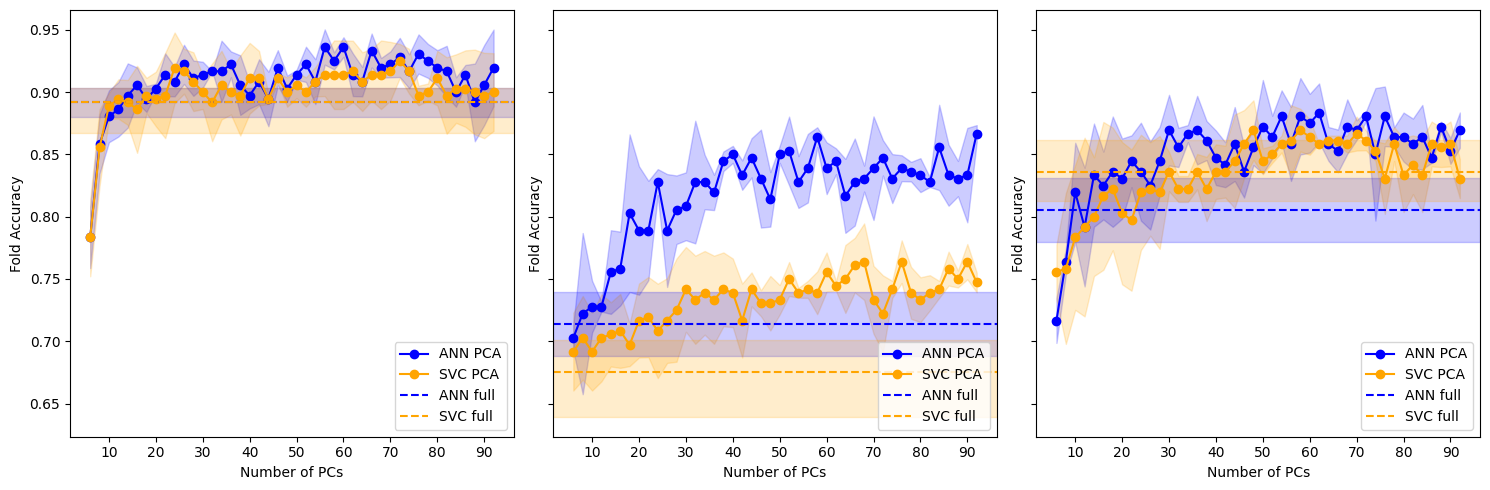

In [4]:
fig, axs = plt.subplots(1, 3, figsize = (15, 5), sharex = True, sharey = True)
ax = axs.ravel()

folds = list(ANN_pca_loaded_performance.keys())
pcs = np.array(list(ANN_pca_loaded_performance[folds[0]][0].keys()))
names = list(ANN_pca_loaded_performance[folds[0]][0][pcs[0]].keys())

plotting_dict = {}

for i in range(len(names)):
    perf_dict = {}
    
    acc_a_overall = []
    acc_s_overall = []
    
    for n in pcs:
        temp_a_acc = []
        temp_s_acc = []

        for f in folds:
            temp_a_acc.append(ANN_pca_loaded_performance[f][0][n][names[i]][-1]["accuracy"])
            temp_s_acc.append(SVC_pca_loaded_performance[f][0][n][names[i]][-1]["accuracy"])

        acc_a_overall.append(temp_a_acc)
        acc_s_overall.append(temp_s_acc)

    acc_a_m = np.mean(np.array(acc_a_overall), axis = 1)
    acc_a_s = np.std(np.array(acc_a_overall), axis = 1)

    acc_s_m = np.mean(np.array(acc_s_overall), axis = 1)
    acc_s_s = np.std(np.array(acc_s_overall), axis = 1)
    
    
    ax[i].plot(pcs, acc_a_m, "-o", label = "ANN PCA", color = "blue")
    ax[i].fill_between(pcs, acc_a_m - acc_a_s, acc_a_m + acc_a_s, alpha = 0.2, color = "blue")

    ax[i].plot(pcs, acc_s_m, "-o", label = "SVC PCA", color = "orange")
    ax[i].fill_between(pcs, acc_s_m - acc_s_s, acc_s_m + acc_s_s, alpha = 0.2, color = "orange")
    
    perf_dict["ANN PCA"] = [acc_a_m, acc_a_s]
    perf_dict["SVC PCA"] = [acc_s_m, acc_s_s]
    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    
    acc_fa = []
    acc_fs = []
    
    for f in folds:
        acc_fa.append(ANN_full_loaded_performance[f][names[i]][-1]["accuracy"])
        acc_fs.append(SVC_full_loaded_performance[f][names[i]][-1]["accuracy"])

    ax[i].axhline(np.mean(acc_fa), linestyle = "--", label = "ANN full", color = "blue")
    ax[i].axhspan(np.mean(acc_fa) - np.std(acc_fa), np.mean(acc_fa) + np.std(acc_fa), alpha = 0.2, color = "blue")
    
    ax[i].axhline(np.mean(acc_fs), linestyle = "--", label = "SVC full", color = "orange")
    ax[i].axhspan(np.mean(acc_fs) - np.std(acc_fs), np.mean(acc_fs) + np.std(acc_fa), alpha = 0.2, color = "orange")
    
    ax[i].set_xlabel("Number of PCs")
    ax[i].set_ylabel("Fold Accuracy")
    ax[i].legend(loc = "lower right")
    ax[i].xaxis.set_major_locator(ticker.MultipleLocator(10))
    
    perf_dict["ANN full"] = acc_fa
    perf_dict["SVC full"] = acc_fs
    plotting_dict[names[i]] = perf_dict

plt.tight_layout()

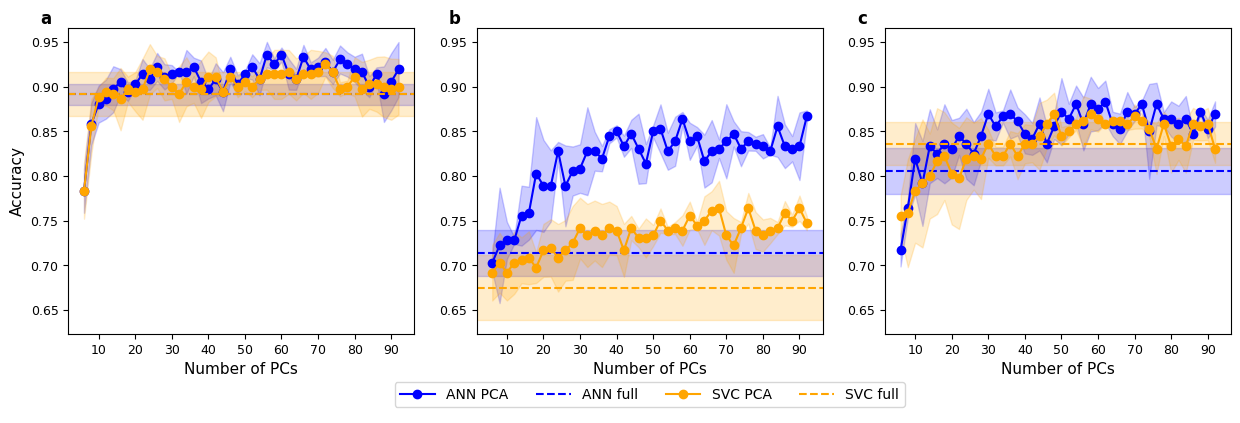

In [5]:
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


fig = plt.figure(figsize=(15, 5))

# Two rows: top = plots (1x4), bottom = external legend
outer = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[1.0, 0.12], hspace=0.25)

# Subgrid for the 4 horizontally arranged plots
plots_gs = outer[0].subgridspec(1, 3, wspace=0.18)

# Right three: share x among themselves (not with ax_top)
ax_b1 = fig.add_subplot(plots_gs[0, 0])
ax_b2 = fig.add_subplot(plots_gs[0, 1], sharex=ax_b1, sharey = ax_b1)
ax_b3 = fig.add_subplot(plots_gs[0, 2], sharex=ax_b1, sharey = ax_b1)

# -----------------------------
# Plotting
# -----------------------------

# Panels b–d: shared x (within the right three only)
ax_perf_list = [ax_b1, ax_b2, ax_b3]
for i, ax in enumerate(ax_perf_list):
    data = plotting_dict[names[i]]
    color_list = ["blue", "orange"]
    keys = list(data.keys())
    for k in range(len(keys)-2):
        arr_dt = data[keys[k]]
        arr_m = np.mean(data[keys[k+2]])
        arr_s = np.std(data[keys[k+2]])
        c = color_list[k]
        ax.plot(pcs, arr_dt[0], "-o", color=c, label=keys[k])
        ax.fill_between(pcs, arr_dt[0] - arr_dt[1],
                        arr_dt[0] + arr_dt[1], color=c, alpha=0.2)
        ax.axhline(y = arr_m, linestyle="--", color=c, label=keys[k+2])
        ax.axhspan(arr_m - arr_s, arr_m + arr_s, alpha = 0.2, color = c)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
        if i == 0:
            ax.set_ylabel("Accuracy")
        ax.set_xlabel("Number of PCs")

# -----------------------------
# External legend row
# -----------------------------
ax_leg = fig.add_subplot(outer[1, 0])
ax_leg.axis("off")

# Build unique legend entries (using the last panel’s handles)
handles, labels = [], []
h, l = ax_b3.get_legend_handles_labels()
for hh, ll in zip(h, l):
    if ll not in labels:
        handles.append(hh)
        labels.append(ll)

ax_leg.legend(handles, labels,
              loc="center",
              ncol=4,
              frameon=True,
              handlelength=2.5)

# Panel labels a–d
labels = ["a", "b", "c"]
axs = [ax_b1, ax_b2, ax_b3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_3.svg", bbox_inches="tight")
plt.show()

# ANN - 24 Performance evaluation

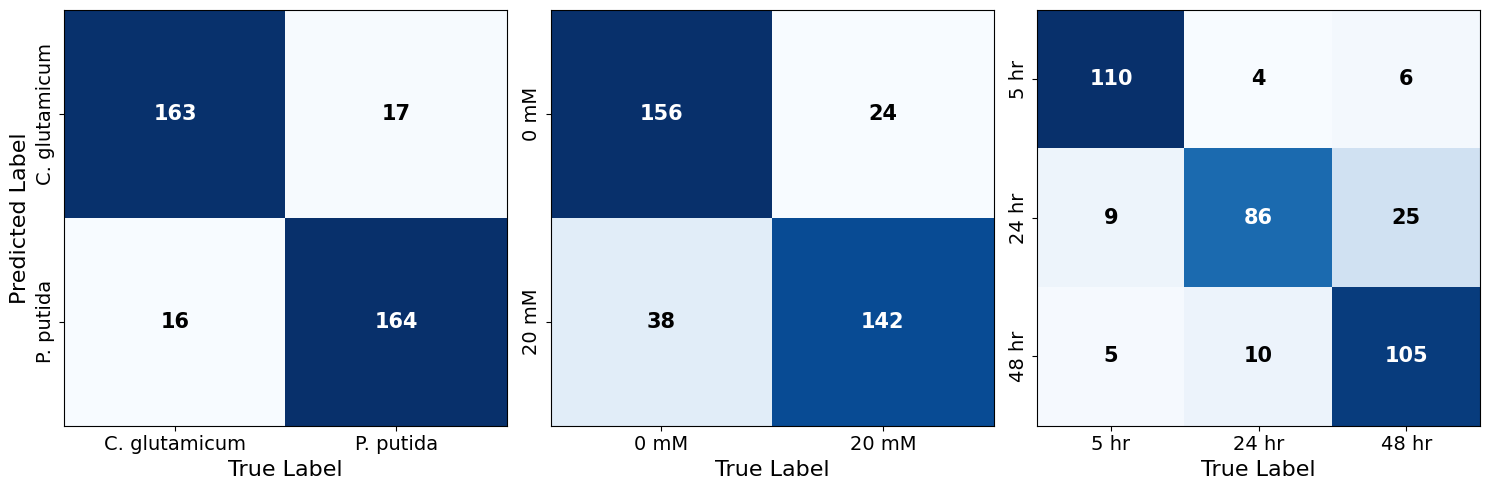

In [6]:
fig, axs = plt.subplots(1, 3, figsize = (15, 5))#, constrained_layout = True)
ax = axs.ravel()

htm_dict = ANN_pca_loaded_performance

labels_list = [["C. glutamicum", "P. putida"], ["0 mM", "20 mM"], ["5 hr", "24 hr", "48 hr"]]
complete_confusion_plot = []

for k in range(len(names)):
    
    htm_list = []
    
    for f in folds:
        
        htm_list.append(htm_dict[f][0][24][names[k]][-2])
    
    htm_list = np.sum(np.array(htm_list), axis = 0)
    acc = np.sum(np.diagonal(htm_list))/np.sum(htm_list)
    complete_confusion_plot.append(htm_list)
    im3 = ax[k].imshow(htm_list, aspect = "auto", cmap = "Blues")
    data = htm_list
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if i == j:
                c = "white"
            else:
                c = "black"
            ax[k].text(j, i, str(int(data[i, j])),
                    ha="center", va="center", fontsize = 15, fontweight = "bold",
                      color = c)
    
    
    ax[k].set_xticks(range(len(htm_list)))
    ax[k].set_yticks(range(len(htm_list)))

    ax[k].set_xticklabels(labels_list[k], fontsize = 14)
    ax[k].set_yticklabels(labels_list[k], fontsize = 14, rotation = 90, va = "center")
    ax[k].set_yticklabels(labels_list[k], fontsize = 14, rotation = 90, va = "center")

    
    #ax[k].set_title(names[k], fontweight = "bold", fontsize = 20)
    ax[k].set_xlabel("True Label", fontsize = 16)
    if k == 0:
        ax[k].set_ylabel("Predicted Label", fontsize = 16)
    
plt.tight_layout()

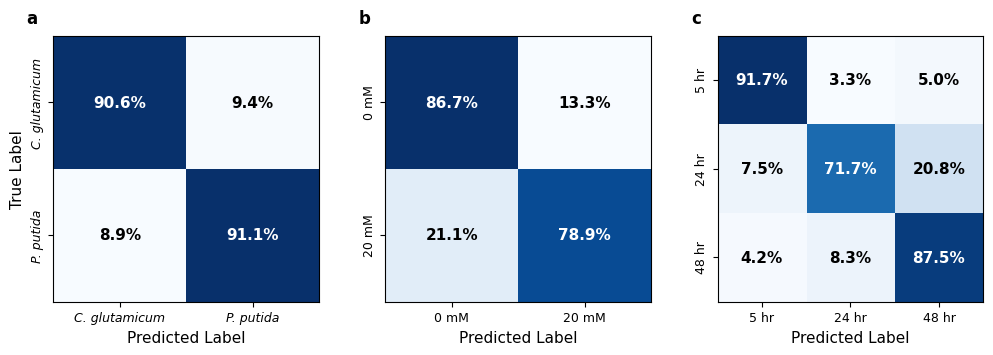

In [7]:
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


# -------- CONFUSION MATRICES (replace with your own) --------
cm1 = complete_confusion_plot[0]

cm2 = complete_confusion_plot[1]

cm3 = complete_confusion_plot[2]

# -------- FIGURE + GRID --------
fig = plt.figure(figsize=(12, 4))
gs = GridSpec(nrows=1, ncols=3, wspace=0.25)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

# ==============================================================
# ------------------ CONFUSION MATRIX 1 (2×2) ------------------
# ==============================================================

im1 = ax1.imshow(cm1, cmap="Blues", aspect="equal")

ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
labels_s = ["C. glutamicum", "P. putida"]
ax1.set_xticklabels(labels_s, fontstyle = "italic")
ax1.set_yticklabels(labels_s, rotation = 90, va = "center", fontstyle = "italic")

ax1.set_xlabel("Predicted Label")
ax1.set_ylabel("True Label")

data = cm1
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if i == j:
            c = "white"
        else:
            c = "black"
        ax1.text(j, i, str(round(data[i, j]*100/180, 1)) + "%",
                ha="center", va="center", fontsize = 11, fontweight = "bold",
                  color = c)


for spine in ax1.spines.values():
    spine.set_visible(True)

# ==============================================================
# ------------------ CONFUSION MATRIX 2 (2×2) ------------------
# ==============================================================

im2 = ax2.imshow(cm2, cmap="Blues", aspect="equal")

ax2.set_xticks([0, 1])
ax2.set_yticks([0, 1])
labels_m = ["0 mM", "20 mM"]
ax2.set_xticklabels(labels_m)
ax2.set_yticklabels(labels_m, rotation = 90, va = "center")

ax2.set_xlabel("Predicted Label")
#ax2.set_ylabel("True")

data = cm2
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if i == j:
            c = "white"
        else:
            c = "black"
        ax2.text(j, i, str(round(data[i, j]*100/180, 1)) + "%",
                ha="center", va="center", fontsize = 11, fontweight = "bold",
                  color = c)

for spine in ax2.spines.values():
    spine.set_visible(True)

# ==============================================================
# ------------------ CONFUSION MATRIX 3 (3×3) ------------------
# ==============================================================

im3 = ax3.imshow(cm3, cmap="Blues", aspect="equal")

ax3.set_xticks([0, 1, 2])
ax3.set_yticks([0, 1, 2])
labels_a = ["5 hr", "24 hr", "48 hr"]
ax3.set_xticklabels(labels_a)
ax3.set_yticklabels(labels_a, rotation = 90, va = "center")

ax3.set_xlabel("Predicted Label")
#ax3.set_ylabel("True")

data = cm3
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        if i == j:
            c = "white"
        else:
            c = "black"
        ax3.text(j, i, str(round(data[i, j]*100/120, 1)) + "%",
                ha="center", va="center", fontsize = 11, fontweight = "bold",
                  color = c)

for spine in ax3.spines.values():
    spine.set_visible(True)

# -------- Show --------

labels = ["a", "b", "c"]
axs = [ax1, ax2, ax3]

for ax, label in zip(axs, labels):
    ax.text(
        -0.1, 1.1, label,
        transform=ax.transAxes,
        fontsize=PANEL_LABEL_SIZE,
        fontweight="bold",
        va="top"
    )

plt.savefig("Paper and SI images\\Figure_4.svg", bbox_inches="tight")
plt.show()

In [8]:
# filename = "ANN_24PCA_SO_nCV_03112026_typeO.pkl"

# with open(filename, "rb") as file:
#     ANN_24_performance = pickle.load(file)

# print(ANN_24_performance.keys())

In [9]:
bgv_dict = {}
for k in range(len(names)):
    folds = list(ANN_pca_loaded_performance.keys())
    comp_mispredict_list = []

    for f in folds:
        y_test_full = ANN_pca_loaded_performance[f][6]
        y_predict = ANN_pca_loaded_performance[f][0][24][names[k]][4]

        mispredict_index = y_test_full[:,k] != y_predict
        other_labels = np.delete(y_test_full[mispredict_index,:], k, axis = 1)

        for i in range(len(other_labels)):
            comp_mispredict_list.append(other_labels[i,:])

    comp_mispredict_list = np.array(comp_mispredict_list)

    row = len(np.unique(comp_mispredict_list[:,0]))
    col = len(np.unique(comp_mispredict_list[:,1]))

    bar_graph_val = np.zeros((row, col))

    for i in range(len(comp_mispredict_list)):
        r, c = comp_mispredict_list[i,:]
        bar_graph_val[r, c] += 1
    print(bar_graph_val.shape)
    bgv_dict[names[k]] = bar_graph_val

(2, 3)
(2, 3)
(2, 2)


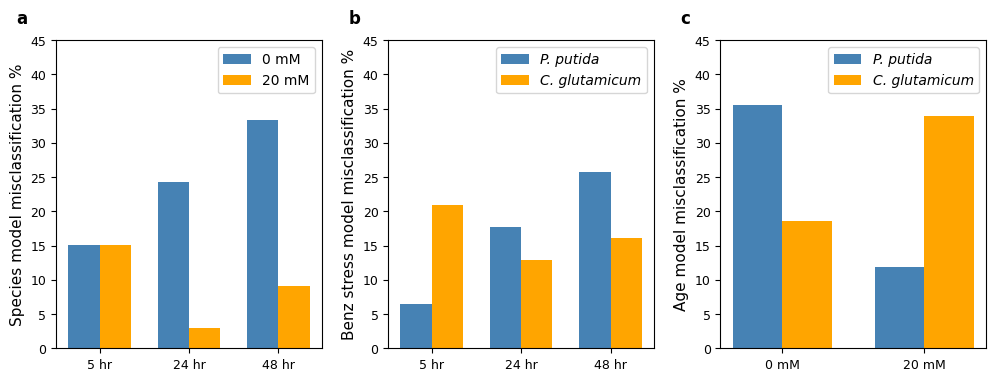

In [10]:
# -------------------
# Styling
# -------------------
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})


# --- Data ---
# Panels A & B: 3 groups × 2 classes
groups_3 = ['Group 1', 'Group 2', 'Group 3']
x3 = np.arange(len(groups_3))
width = 0.35

class0_s = bgv_dict["species"][0,:]*100/np.sum(bgv_dict["species"])
class20_s = bgv_dict["species"][1,:]*100/np.sum(bgv_dict["species"])

classP_m = bgv_dict["metabolites"][0,:]*100/np.sum(bgv_dict["metabolites"])
classC_m = bgv_dict["metabolites"][1,:]*100/np.sum(bgv_dict["metabolites"])

# Panel C: 2 groups × 2 classes
groups_2 = ['Group 1', 'Group 2']   # <- only two groups here
x2 = np.arange(len(groups_2))

classP_a = bgv_dict["age"][0,:]*100/np.sum(bgv_dict["age"])
classC_a = bgv_dict["age"][1,:]*100/np.sum(bgv_dict["age"])

# --- Figure and GridSpec layout (three plots in a row) ---
fig = plt.figure(figsize=(12, 4))
gs = GridSpec(nrows=1, ncols=3, width_ratios=[1, 1, 1], wspace=0.25)

# Axes
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1], sharey=ax1)
ax3 = fig.add_subplot(gs[0, 2], sharey=ax1)

# ---- Panel A (3 groups) ----
b1_a = ax1.bar(x3 - width/2, class0_s, width, label='0 mM', color='steelblue')
b2_a = ax1.bar(x3 + width/2, class20_s, width, label='20 mM', color='orange')
ax1.set_xticks(x3)
ax1.set_xticklabels(["5 hr", "24 hr", "48 hr"])
ax1.grid(False)
ax1.legend(loc='upper right')
ax1.set_ylabel('Species model misclassification %')
ax1.set_ylim([0, 45])

# ---- Panel B (3 groups) ----
b1_b = ax2.bar(x3 - width/2, classP_m, width, label='P. putida', color='steelblue')
b2_b = ax2.bar(x3 + width/2, classC_m, width, label='C. glutamicum', color='orange')
ax2.set_ylabel('Benz stress model misclassification %')
ax2.set_xticks(x3)
ax2.set_xticklabels(["5 hr", "24 hr", "48 hr"])
ax2.grid(False)
ax2.legend(loc='upper right', prop={'style': 'italic'})

# ---- Panel C (2 groups) ----
b1_c = ax3.bar(x2 - width/2, classP_a, width, label='P. putida', color='steelblue')
b2_c = ax3.bar(x2 + width/2, classC_a, width, label='C. glutamicum', color='orange')
ax3.set_xticks(x2)
ax3.set_xticklabels(["0 mM", "20 mM"])
ax3.set_ylabel('Age model misclassification %')
ax3.grid(False)
ax3.legend(loc='upper right', prop={'style': 'italic'})

labels = ["a", "b", "c"]
axes = [ax1, ax2, ax3]#, ax_r2, ax_r3, ax_r4]

for ax, label in zip(axes, labels):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=PANEL_LABEL_SIZE,
        fontweight="bold",
        va="top"
    )
    
plt.savefig("Paper and SI images\\Figure_5.svg", bbox_inches="tight")
plt.show()